# Exploratory Data Analysis of Crime Patterns: A Temporal, Spatial and Categorical Investigation

# 1. Importing the required libraries and loading the dataset

In [ ]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
import plotly.express as px
import plotly.graph_objects as go

In [ ]:
df = pd.read_csv('dataset_coursework1.csv')

/tmp/ipykernel_1888/995784917.py:1: DtypeWarning: Columns (1) have mixed types. Specify dtype option on import or set low_memory=False.
  df = pd.read_csv('dataset_coursework1.csv')


# 2. Initial Data Inspection

In [ ]:
df.shape

(508106, 30)

In [ ]:
df.columns

Index(['Incident ID', 'Offence Code', 'CR Number', 'Dispatch Date / Time',
       'Start_Date_Time', 'End_Date_Time', 'NIBRS Code', 'Victims',
       'Crime Name1', 'Crime Name2', 'Crime Name3', 'Police District Name',
       'Block Address', 'City', 'State', 'Zip Code', 'Agency', 'Place',
       'Sector', 'Beat', 'PRA', 'Address Number', 'Street Prefix',
       'Street Name', 'Street Suffix', 'Street Type', 'Latitude', 'Longitude',
       'Police District Number', 'Location'],
      dtype='object')

In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 508106 entries, 0 to 508105
Data columns (total 30 columns):
 #   Column                  Non-Null Count   Dtype  
---  ------                  --------------   -----  
 0   Incident ID             508106 non-null  int64  
 1   Offence Code            508106 non-null  object 
 2   CR Number               508106 non-null  int64  
 3   Dispatch Date / Time    434701 non-null  object 
 4   Start_Date_Time         508106 non-null  object 
 5   End_Date_Time           225662 non-null  object 
 6   NIBRS Code              508106 non-null  object 
 7   Victims                 508106 non-null  int64  
 8   Crime Name1             508106 non-null  object 
 9   Crime Name2             508106 non-null  object 
 10  Crime Name3             508106 non-null  object 
 11  Police District Name    506564 non-null  object 
 12  Block Address           468302 non-null  object 
 13  City                    508069 non-null  object 
 14  State               

The dataset contains 30 columns. We group them by their analytical purpose to understand how each variable contributes to our research questions.

| Group | Examples | Purpose |
| :--- | :--- | :--- |
| Identifiers & Tracking | `Incident ID`, `CR Number`, `Offence Code`, `NIBRS Code` | Distinguish unique crime reports, tracking numbers, and standardized federal incident classifications. |
| Temporal Attributes | `Dispatch Date / Time`, `Start_Date_Time`, `End_Date_Time` | Track dispatch timing, incident duration, and temporal patterns. |
| Crime Classification & Impact | `Crime Name1`, `Crime Name2`, `Crime Name3`, `Victims` | Categorize crime severity, offense types, and victim count per incident. |
| Geographical & Spatial Coordinates | `Latitude`, `Longitude`, `Location`, `Zip Code`, `City`, `State` | Enable spatial mapping, coordinate clustering, and regional demographic analysis. |
| Law Enforcement Administrative | `Agency`, `Police District Name`, `Police District Number`, `Sector`, `Beat`, `PRA` | Examine police jurisdiction, operational sectors, and patrol beat boundaries. |
| Street & Address Details | `Block Address`, `Address Number`, `Street Prefix`, `Street Name`, `Street Suffix`, `Street Type`, `Place` | Pinpoint exact street-level locations and micro-environments where crimes occur. |

In [ ]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
Incident ID,508106.0,2.013365e+08,1.452671e+05,2.010871e+08,2.012112e+08,2.013340e+08,2.014644e+08,2.015908e+08
CR Number,508106.0,1.976345e+08,6.015008e+07,1.001107e+07,1.800522e+08,2.100215e+08,2.400055e+08,2.600782e+08
Victims,508106.0,1.021832e+00,1.848346e-01,1.000000e+00,1.000000e+00,1.000000e+00,1.000000e+00,2.200000e+01
Zip Code,504632.0,2.087668e+04,1.332511e+02,6.000000e+00,2.085300e+04,2.087800e+04,2.090400e+04,2.988200e+04
Address Number,468445.0,8.337491e+03,1.533374e+04,0.000000e+00,1.600000e+03,8.000000e+03,1.240000e+04,2.090600e+06
Latitude,508106.0,3.718591e+01,8.396632e+00,0.000000e+00,3.901501e+01,3.906909e+01,3.914075e+01,3.935124e+01
Longitude,508106.0,-7.337451e+01,1.656777e+01,-7.751670e+01,-7.719640e+01,-7.709800e+01,-7.702660e+01,0.000000e+00


In [ ]:
df.describe(include='all') # include = 'all' considers categorical columns as itself , instead of continuous coulmn

,Incident ID,Offence Code,CR Number,Dispatch Date / Time,Start_Date_Time,End_Date_Time,NIBRS Code,Victims,Crime Name1,Crime Name2,...,PRA,Address Number,Street Prefix,Street Name,Street Suffix,Street Type,Latitude,Longitude,Police District Number,Location
count,5.081060e+05,508106.0,5.081060e+05,434701,508106,225662,508106,508106.000000,508106,508106,...,508097,4.684450e+05,22561,506639,6930,506250,508106.000000,508106.000000,508106,508106
unique,NaN,663.0,NaN,397963,372500,157941,54,NaN,4,54,...,808,NaN,4,8156,6,35,NaN,NaN,8,31194
top,NaN,2305.0,NaN,12/02/2019 04:39:39 PM,01/01/2021 12:00:00 AM,12/02/2019 09:30:00 AM,90Z,NaN,Crime Against Property,All Other Offenses,...,702,NaN,N,GEORGIA,W,RD,NaN,NaN,3D,"(0.0, 0.0)"
freq,NaN,30091.0,NaN,48,57,42,121221,NaN,246236,121221,...,8931,NaN,7886,20785,3912,126012,NaN,NaN,106353,24648
mean,2.013365e+08,NaN,1.976345e+08,NaN,NaN,NaN,NaN,1.021832,NaN,NaN,...,NaN,8.337491e+03,NaN,NaN,NaN,NaN,37.185906,-73.374514,NaN,NaN
std,1.452671e+05,NaN,6.015008e+07,NaN,NaN,NaN,NaN,0.184835,NaN,NaN,...,NaN,1.533374e+04,NaN,NaN,NaN,NaN,8.396632,16.567768,NaN,NaN
min,2.010871e+08,NaN,1.001107e+07,NaN,NaN,NaN,NaN,1.000000,NaN,NaN,...,NaN,0.000000e+00,NaN,NaN,NaN,NaN,0.000000,-77.516700,NaN,NaN
25%,2.012112e+08,NaN,1.800522e+08,NaN,NaN,NaN,NaN,1.000000,NaN,NaN,...,NaN,1.600000e+03,NaN,NaN,NaN,NaN,39.015010,-77.196400,NaN,NaN
50%,2.013340e+08,NaN,2.100215e+08,NaN,NaN,NaN,NaN,1.000000,NaN,NaN,...,NaN,8.000000e+03,NaN,NaN,NaN,NaN,39.069090,-77.098000,NaN,NaN
75%,2.014644e+08,NaN,2.400055e+08,NaN,NaN,NaN,NaN,1.000000,NaN,NaN,...,NaN,1.240000e+04,NaN,NaN,NaN,NaN,39.140750,-77.026600,NaN,NaN


In [ ]:
df.head()

,Incident ID,Offence Code,CR Number,Dispatch Date / Time,Start_Date_Time,End_Date_Time,NIBRS Code,Victims,Crime Name1,Crime Name2,...,PRA,Address Number,Street Prefix,Street Name,Street Suffix,Street Type,Latitude,Longitude,Police District Number,Location
0,201590757,9108,260040147,NaN,09/14/2026 08:44:00 PM,NaN,90Z,1,Crime Against Society,All Other Offenses,...,148,1000.0,NaN,MILESTONE,NaN,DR,39.04565,-76.9920,3D,"(39.0457, -76.992)"
1,201590749,2901,260040333,09/14/2026 07:46:02 PM,09/14/2026 07:46:00 PM,NaN,290,1,Crime Against Property,Destruction/Damage/Vandalism of Property,...,702,13000.0,NaN,MIDDLEBROOK,NaN,RD,39.18138,-77.2695,5D,"(39.1814, -77.2695)"
2,201590742,9199,260040311,09/14/2026 06:01:40 PM,09/14/2026 06:01:00 PM,NaN,90Z,1,Crime Against Society,All Other Offenses,...,148,1000.0,NaN,MILESTONE,NaN,DR,39.04565,-76.9920,3D,"(39.0457, -76.992)"
3,201590754,9108,260040316,NaN,09/14/2026 06:00:00 PM,09/14/2026 07:00:00 PM,90Z,1,Crime Against Society,All Other Offenses,...,425,200.0,NaN,PARAMOUNT PARK,NaN,DR,39.15876,-77.2224,6D,"(39.1588, -77.2224)"
4,201590766,9199,260040314,09/14/2026 05:52:52 PM,09/14/2026 05:52:00 PM,NaN,90Z,1,Crime Against Society,All Other Offenses,...,140,10100.0,NaN,NEW HAMPSHIRE,NaN,AVE,39.02039,-76.9766,3D,"(39.0204, -76.9766)"


In [ ]:
df.tail()

,Incident ID,Offence Code,CR Number,Dispatch Date / Time,Start_Date_Time,End_Date_Time,NIBRS Code,Victims,Crime Name1,Crime Name2,...,PRA,Address Number,Street Prefix,Street Name,Street Suffix,Street Type,Latitude,Longitude,Police District Number,Location
508101,201089700,2308,16036427,NaN,07/01/2016 12:00:00 AM,07/05/2016 12:00:00 AM,23D,1,Crime Against Property,Theft from Building,...,036,4100.0,NaN,LELAND,NaN,ST,38.98565,-77.0818,2D,"(38.9857, -77.0818)"
508102,201248224,9105,190033731,07/16/2019 10:55:43 AM,07/01/2016 12:00:00 AM,NaN,90Z,1,Crime Against Society,All Other Offenses,...,276,1.0,NaN,MONROE,NaN,PL,39.08354,-77.1469,1D,"(39.0835, -77.1469)"
508103,201100330,2589,16048345,NaN,07/01/2016 12:00:00 AM,07/31/2016 12:00:00 AM,250,1,Crime Against Property,Counterfeiting/Forgery,...,276,1.0,NaN,COURTHOUSE,NaN,SQ,39.08418,-77.1529,1D,"(39.0842, -77.1529)"
508104,201103549,2699,16053730,NaN,07/01/2016 12:00:00 AM,09/30/2016 11:59:00 PM,26A,1,Crime Against Property,False Pretenses/Swindle/Confidence Game,...,298,13100.0,NaN,OKINAWA,NaN,AVE,39.07045,-77.1214,1D,"(39.0705, -77.1214)"
508105,201093158,2604,16040595,NaN,07/01/2016 12:00:00 AM,08/10/2016 03:00:00 PM,26C,1,Crime Against Property,Impersonation,...,036,4000.0,NaN,UNDERWOOD,NaN,ST,38.98300,-77.0794,2D,"(38.983, -77.0794)"


### The dataset has 508106 rows and 30 columns out of which 3 columns are integer (int64), 4 are float (float64) and 23 of them are of the type object


# 3. Data Integrity Check

## 3.1. Missing Values Check

In [ ]:
df.isnull().sum()

,0
Incident ID,0
Offence Code,0
CR Number,0
Dispatch Date / Time,73405
Start_Date_Time,0
End_Date_Time,282444
NIBRS Code,0
Victims,0
Crime Name1,0
Crime Name2,0


In [ ]:
df.isnull().sum()[df.isnull().sum() > 0]

,0
Dispatch Date / Time,73405
End_Date_Time,282444
Police District Name,1542
Block Address,39804
City,37
State,9509
Zip Code,3474
PRA,9
Address Number,39661
Street Prefix,485545


In [ ]:
missing_percentage = (df.isnull().sum()/len(df)).mul(100)
missing_percentage[missing_percentage>0].sort_values(ascending=False)

,0
Street Suffix,98.636111
Street Prefix,95.559785
End_Date_Time,55.587614
Dispatch Date / Time,14.446789
Block Address,7.833798
Address Number,7.805655
State,1.871460
Zip Code,0.683716
Street Type,0.365278
Police District Name,0.303480


## 3.2. Spatial Noise and Junk Values Audit
We investigate potential geocoding errors by auditing the spatial coordinate columns (`Latitude`, `Longitude`, and `Location`) for default `(0.0, 0.0)` anomalies.

In [ ]:
invalid_coords = (df['Latitude'] == 0.0) & (df['Longitude'] == 0.0)
invalid_count = invalid_coords.sum()
invalid_count


np.int64(24648)

In [ ]:
invalid_location_string = df['Location'].astype(str).str.contains(r'0\.0.*0\.0', regex=True)
print(f"Count of '(0.0, 0.0)' string patterns in Location: {invalid_location_string.sum()}")

Count of '(0.0, 0.0)' string patterns in Location: 24648


In [ ]:
total_records = len(df)

coord_invalid_count = ((df['Latitude'] == 0.0) & (df['Longitude'] == 0.0)).sum()
coord_invalid_pct = (coord_invalid_count / total_records) * 100

location_invalid_count = df['Location'].astype(str).str.contains(r'0\.0.*0\.0', regex=True).sum()
location_invalid_pct = (location_invalid_count / total_records) * 100

print(f"Invalid Coordinates: {coord_invalid_count} records ({coord_invalid_pct:.2f}%)")
print(f"Invalid Location Strings: {location_invalid_count} records ({location_invalid_pct:.2f}%)")

Invalid Coordinates: 24648 records (4.85%)
Invalid Location Strings: 24648 records (4.85%)


## 3.3. Duplicate records check

In [ ]:
df.duplicated().sum()         # Check for duplicate rows across the entire dataset

np.int64(0)

In [ ]:
df['Incident ID'].duplicated().sum()

np.int64(40505)

In [ ]:
df['Incident ID'].nunique()

467601

## 3.4. Categorical Columns Investigation

In [ ]:
cat_summary = []
for col in df.select_dtypes(include=['object', 'category']).columns:
    cat_summary.append({
        'Column': col,
        'Unique Values': df[col].nunique(),
    })

cat_df = pd.DataFrame(cat_summary)
cat_df.sort_values(by='Unique Values', ascending=False, inplace=True)
cat_df.reset_index(drop=True, inplace=True)
cat_df

,Column,Unique Values
0,Dispatch Date / Time,397963
1,Start_Date_Time,372500
2,End_Date_Time,157941
3,Location,31194
4,Block Address,23491
5,Street Name,8156
6,PRA,808
7,Offence Code,663
8,Crime Name3,360
9,City,314


In [ ]:
categorical_columns = [
    'Crime Name1',
    'Crime Name2',
    'Crime Name3',
     'Agency',
    'Police District Name',
    'Police District Number',
    'City',
    'State',
    'Place',
    'Sector'
]

for col in categorical_columns:
    #print(f"\n{'=' * 40}")
    print(f"Column: {col}")
    #print('=' * 40)

    display(df[col].value_counts(dropna=False).to_frame('Count'))

Column: Crime Name1


,Count
Crime Name1,
Crime Against Property,246236
Crime Against Society,202327
Crime Against Person,53385
Crime Against Not a Crime,6158


Column: Crime Name2


,Count
Crime Name2,
All Other Offenses,121221
Theft From Motor Vehicle,41308
Simple Assault,37170
Shoplifting,35011
Destruction/Damage/Vandalism of Property,32080
Drug/Narcotic Violations,27827
All other Larceny,22999
Driving Under the Influence,20401
Motor Vehicle Theft,17997


Column: Crime Name3


,Count
Crime Name3,
LARCENY - FROM AUTO,41308
LARCENY - SHOPLIFTING,35011
POLICE INFORMATION,33174
ASSAULT - 2ND DEGREE,31826
LARCENY (DESCRIBE OFFENSE),20699
...,...
COMPOUNDING CRIME,1
DAMAGE PROPERTY - PUBLIC-WITH EXPLOSIVE,1
TRANSPORTING DANGEROUS MATERIALS,1


... (10 outputs left out)

Column: Place


,Count
Place,
Residence - Single Family,52419
Residence - Apartment/Condo,49545
Street - In vehicle,44807
Other/Unknown,40895
Street - Residential,35054
...,...
Camp / Campground,9
Military Installation,9
Rest Area,6


Column: Sector


,Count
Sector,
A,49546
P,48614
G,45047
D,41702
I,39828
L,39073
R,36680
K,33817
N,33117


In [ ]:
for col in categorical_columns:

    counts = df[col].value_counts(dropna=False)

    summary = pd.DataFrame({'Count': counts,'Percentage': ((counts / len(df)) * 100).round(2)})

    print(f"\nColumn: {col}")
    display(summary)


Column: Crime Name1


,Count,Percentage
Crime Name1,,
Crime Against Property,246236,48.46
Crime Against Society,202327,39.82
Crime Against Person,53385,10.51
Crime Against Not a Crime,6158,1.21



Column: Crime Name2


,Count,Percentage
Crime Name2,,
All Other Offenses,121221,23.86
Theft From Motor Vehicle,41308,8.13
Simple Assault,37170,7.32
Shoplifting,35011,6.89
Destruction/Damage/Vandalism of Property,32080,6.31
Drug/Narcotic Violations,27827,5.48
All other Larceny,22999,4.53
Driving Under the Influence,20401,4.02
Motor Vehicle Theft,17997,3.54



Column: Crime Name3


,Count,Percentage
Crime Name3,,
LARCENY - FROM AUTO,41308,8.13
LARCENY - SHOPLIFTING,35011,6.89
POLICE INFORMATION,33174,6.53
ASSAULT - 2ND DEGREE,31826,6.26
LARCENY (DESCRIBE OFFENSE),20699,4.07
...,...,...
COMPOUNDING CRIME,1,0.00
DAMAGE PROPERTY - PUBLIC-WITH EXPLOSIVE,1,0.00
TRANSPORTING DANGEROUS MATERIALS,1,0.00


... (10 outputs left out)


Column: Place


,Count,Percentage
Place,,
Residence - Single Family,52419,10.32
Residence - Apartment/Condo,49545,9.75
Street - In vehicle,44807,8.82
Other/Unknown,40895,8.05
Street - Residential,35054,6.90
...,...,...
Camp / Campground,9,0.00
Military Installation,9,0.00
Rest Area,6,0.00



Column: Sector


,Count,Percentage
Sector,,
A,49546,9.75
P,48614,9.57
G,45047,8.87
D,41702,8.21
I,39828,7.84
L,39073,7.69
R,36680,7.22
K,33817,6.66
N,33117,6.52


1. What We Have Done & Analyzed So Far?

**Missing Value Audit:** Quantified missingness across all 30 columns, discovering critical gaps such as End_Date_Time (55.59% missing) and address components like Street Suffix (98.64%) and Street Prefix (95.56%).   
**Spatial Noise & Geocoding Audit:** Identified and calculated exact percentages for spatial anomalies, proving that 24,648 records (4.85%) contain invalid (0.0, 0.0) coordinates and matching location strings.   
**Uniqueness & Duplicate Check:** Verified that the dataset contains 0 full row duplicates, confirming record-level structural uniqueness.   
**Categorical Distribution Analysis:** Profiled key analytical dimensions (Crime Name1, Crime Name2, Crime Name3, Agency, Police District Name, City, State, Place, and Sector) to evaluate category cardinality, spot data entry errors, and assess class distributions.  

# 4. Data Preprocessing

## 4.1 Handling Missing Values

### 4.1.1. Temporal Missingness (End_Date_Time & Dispatch Date / Time)
In crime datasets, End_Date_Time is frequently unrecorded if an incident's exact conclusion time is unknown or if it was logged as a single-point event (Start_Date_Time). Similarly, dispatch timestamps can be missing for walk-in reports or self-initiated police actions.

Cleaning Strategy: Do not drop these rows, as doing over 50% data deletion would destroy overall crime volume analysis. Instead, convert them to proper datetime objects (with NaT for missing values) so temporal queries ignore them gracefully.

In [ ]:
df_eda = df.copy()

#df_eda.drop(columns=['weight'], inplace=True)

In [ ]:
date_columns = [
    'Start_Date_Time',
    'End_Date_Time',
    'Dispatch Date / Time'
]

print("Dataset shape before preprocessing:", df_eda.shape)

for col in date_columns:
    print(f"\n{col}")
    print("Missing values:", df_eda[col].isna().sum())
    print("Missing percentage:", round(df_eda[col].isna().mean() * 100, 2), "%")
    print("Data type:", df_eda[col].dtype)

Dataset shape before preprocessing: (508106, 30)

Start_Date_Time
Missing values: 0
Missing percentage: 0.0 %
Data type: object

End_Date_Time
Missing values: 282444
Missing percentage: 55.59 %
Data type: object

Dispatch Date / Time
Missing values: 73405
Missing percentage: 14.45 %
Data type: object


In [ ]:
for col in date_columns:
    print(f"\nFirst 10 values in {col}:")
    print(df_eda[col].head(10).to_list())


First 10 values in Start_Date_Time:
['09/14/2026 08:44:00 PM', '09/14/2026 07:46:00 PM', '09/14/2026 06:01:00 PM', '09/14/2026 06:00:00 PM', '09/14/2026 05:52:00 PM', '09/14/2026 05:34:00 PM', '09/14/2026 04:31:00 PM', '09/14/2026 03:54:00 PM', '09/14/2026 03:54:00 PM', '09/14/2026 03:39:00 PM']

First 10 values in End_Date_Time:
[nan, nan, nan, '09/14/2026 07:00:00 PM', nan, nan, nan, nan, nan, nan]

First 10 values in Dispatch Date / Time:
[nan, '09/14/2026 07:46:02 PM', '09/14/2026 06:01:40 PM', nan, '09/14/2026 05:52:52 PM', '09/14/2026 05:34:24 PM', nan, '09/14/2026 03:54:56 PM', '09/14/2026 03:54:06 PM', '09/14/2026 03:39:27 PM']


In [ ]:
date_format = '%m/%d/%Y %I:%M:%S %p'

for col in date_columns:
    parsed_dates = pd.to_datetime(
        df_eda[col],
        format=date_format,
        errors='coerce'
    )

    original_non_missing = df_eda[col].notna().sum()
    conversion_failures = (
        df_eda[col].notna() & parsed_dates.isna()
    ).sum()

    print(f"\n{col}")
    print("Original non-missing values:", original_non_missing)
    print("Conversion failures:", conversion_failures)
    print(
        "Conversion failure percentage:",
        round(conversion_failures / max(original_non_missing, 1) * 100, 2),
        "%"
    )


Start_Date_Time
Original non-missing values: 508106
Conversion failures: 0
Conversion failure percentage: 0.0 %

End_Date_Time
Original non-missing values: 225662
Conversion failures: 0
Conversion failure percentage: 0.0 %

Dispatch Date / Time
Original non-missing values: 434701
Conversion failures: 0
Conversion failure percentage: 0.0 %


In [ ]:
date_format = '%m/%d/%Y %I:%M:%S %p'

for col in date_columns:
    df_eda[col] = pd.to_datetime(
        df_eda[col],
        format=date_format,
        errors='coerce'
    )

In [ ]:
print("Dataset shape after datetime conversion:", df_eda.shape)

for col in date_columns:
    print(f"\n{col}")
    print("Data type:", df_eda[col].dtype)
    print("Missing values:", df_eda[col].isna().sum())

Dataset shape after datetime conversion: (508106, 30)

Start_Date_Time
Data type: datetime64[ns]
Missing values: 0

End_Date_Time
Data type: datetime64[ns]
Missing values: 282444

Dispatch Date / Time
Data type: datetime64[ns]
Missing values: 73405


**From Text to Timestamps**

The original CSV dataset stored the three temporal columns as text (object data type). We converted them into Pandas datetime objects (datetime64[ns]) so that Python could recognise and process them as actual dates and times. This enables operations such as extracting years, months, days and hours, as well as calculating time differences.

**Handling Missing and Invalid Values (errors='coerce')**

We used errors='coerce' during conversion so that any missing or unrecognisable date values would be represented as NaT (Not a Time), the datetime equivalent of NaN. Before conversion, we validated the specified date format against all existing non-missing values and found zero conversion failures. Therefore, no additional missing values were introduced, and all pre-existing missing timestamps were preserved.

### 4.1.2. Dropping sparse and redundant columns
Street Suffix and Street Prefix (**Extreme Data Sparsity**): Both features suffer from critical missingness—Street Suffix is missing in 98.64% of records and Street Prefix in 95.56%. Retaining columns with over 95% null values introduces severe noise and zero analytical signal. Removing them is a rigorous feature reduction step that streamlines the dataset without deleting any core crime incident records, perfectly upholding our strategy to preserve row integrity.

Location (**Dimensional Redundancy**): The Location column contains combined text strings that duplicate the exact numerical spatial data already captured by Latitude and Longitude. Dropping this redundant composite string eliminates feature duplication while preserving full spatial mapping and hotspot analysis capabilities through standardized numeric coordinates.

In [ ]:
sparse_columns = ['Street Suffix', 'Street Prefix']

for col in sparse_columns:
    missing = df_eda[col].isna().sum()
    non_missing = df_eda[col].notna().sum()

    print(f"\n{col}")
    print("Missing values:", missing)
    print("Non-missing values:", non_missing)
    print("Missing percentage:", round(df_eda[col].isna().mean() * 100, 2), "%")
    print("Unique non-missing values:", df_eda[col].nunique())
    print("Sample values:", df_eda[col].dropna().unique()[:10])


Street Suffix
Missing values: 501176
Non-missing values: 6930
Missing percentage: 98.64 %
Unique non-missing values: 6
Sample values: ['E' 'W' 'N' 'S' 'NW' 'NE']

Street Prefix
Missing values: 485545
Non-missing values: 22561
Missing percentage: 95.56 %
Unique non-missing values: 4
Sample values: ['W' 'E' 'N' 'S']


In [ ]:
print("Location data type:", df_eda['Location'].dtype)

print("\nMissing Location values:")
print(df_eda['Location'].isna().sum())

print("\nSample Location values:")
print(df_eda['Location'].dropna().head(10).to_list())

print("\nSample Latitude and Longitude values:")
print(df_eda[['Latitude', 'Longitude']].head(10))

Location data type: object

Missing Location values:
0

Sample Location values:
['    (39.0457, -76.992)', '    (39.1814, -77.2695)', '    (39.0457, -76.992)', '    (39.1588, -77.2224)', '    (39.0204, -76.9766)', '    (38.9916, -77.0266)', '    (39.0017, -77.1097)', '    (39.2375, -77.2779)', '    (39.1018, -77.2003)', '    (39.182, -77.2787)']

Sample Latitude and Longitude values:
   Latitude  Longitude
0  39.04565   -76.9920
1  39.18138   -77.2695
2  39.04565   -76.9920
3  39.15876   -77.2224
4  39.02039   -76.9766
5  38.99163   -77.0266
6  39.00170   -77.1097
7  39.23749   -77.2779
8  39.10179   -77.2003
9  39.18195   -77.2787


In [ ]:
location_coordinates = df_eda['Location'].str.extract(
    r'\(\s*(-?\d+(?:\.\d+)?)\s*,\s*(-?\d+(?:\.\d+)?)\s*\)'
)

location_coordinates.columns = ['Location_Latitude', 'Location_Longitude']

valid = (
    location_coordinates.notna().all(axis=1)
    & df_eda[['Latitude', 'Longitude']].notna().all(axis=1)
)

tolerance = 0.0001

latitude_match = (
    (location_coordinates['Location_Latitude'].astype(float)
     - df_eda['Latitude']).abs() <= tolerance
)

longitude_match = (
    (location_coordinates['Location_Longitude'].astype(float)
     - df_eda['Longitude']).abs() <= tolerance
)

matches = valid & latitude_match & longitude_match

print("Total records:", len(df_eda))
print("Location values successfully parsed:", location_coordinates.notna().all(axis=1).sum())
print("Records with all coordinates available:", valid.sum())
print("Matching coordinate pairs:", matches.sum())
print("Non-matching coordinate pairs:", (valid & ~matches).sum())
print("Coordinate comparison tolerance:", tolerance)

Total records: 508106
Location values successfully parsed: 508106
Records with all coordinates available: 508106
Matching coordinate pairs: 508106
Non-matching coordinate pairs: 0
Coordinate comparison tolerance: 0.0001


In [ ]:
# Identify columns to remove
columns_to_drop = ['Street Suffix', 'Street Prefix', 'Location']

# Record dataset dimensions before removal
shape_before = df_eda.shape

# Drop the selected columns
df_eda.drop(columns=columns_to_drop, inplace=True)

# Record dimensions after removal
shape_after = df_eda.shape

print("Successfully dropped:", columns_to_drop)
print("Shape before:", shape_before)
print("Shape after:", shape_after)
print("Rows removed:", shape_before[0] - shape_after[0])
print("Columns removed:", shape_before[1] - shape_after[1])

Successfully dropped: ['Street Suffix', 'Street Prefix', 'Location']
Shape before: (508106, 30)
Shape after: (508106, 27)
Rows removed: 0
Columns removed: 3


**Handling Sparse and Redundant Columns**

The Street Suffix and Street Prefix columns were removed due to substantial missingness, accounting for 98.64% and 95.56% of their values, respectively. Their limited available information consisted primarily of directional indicators, making them less suitable for further analysis.

The Location column was also removed after verifying its redundancy with Latitude and Longitude. All 508,106 coordinate pairs were successfully extracted and matched the corresponding numerical coordinates within a tolerance of 0.0001. Therefore, retaining Location would duplicate existing geographic information.

The removal of these three columns reduced the dataset from 30 to 27 columns without removing any incident records.

### 4.1.3. Handling spatial noise and coordinate anomalies

An examination of the Latitude and Longitude columns identified 24,648 records (4.85%) containing (0.0, 0.0) coordinate pairs. These coordinates represent a location near the Gulf of Guinea and are geographically inconsistent with the dataset's Maryland-area study region.

To prevent these invalid locations from distorting spatial visualisations and geographic analysis, both coordinate values were replaced with NaN for the affected records. The correction was applied jointly to the coordinate pairs rather than independently to individual zero values.

Following this operation, both coordinate columns contained 24,648 missing values. Importantly, no incident records were deleted, and the dataset retained its original dimensions of 508,106 rows and 27 columns.



In [ ]:
# Inspect spatial coordinate quality
print("Total records:", len(df_eda))

# Count missing coordinates
print("\nMissing coordinates:")
print("Missing Latitude:", df_eda['Latitude'].isna().sum())
print("Missing Longitude:", df_eda['Longitude'].isna().sum())

# Count individual zero values
print("\nIndividual zero coordinates:")
print("Latitude = 0:", (df_eda['Latitude'] == 0).sum())
print("Longitude = 0:", (df_eda['Longitude'] == 0).sum())

# Count records where BOTH coordinates are zero
zero_pair = (
    (df_eda['Latitude'] == 0) &
    (df_eda['Longitude'] == 0)
)

print("\nCoordinate pair anomalies:")
print("(0, 0) records:", zero_pair.sum())
print("(0, 0) percentage:", round(zero_pair.mean() * 100, 2), "%")

# Inspect coordinate ranges
print("\nLatitude statistics:")
print(df_eda['Latitude'].describe())

print("\nLongitude statistics:")
print(df_eda['Longitude'].describe())

Total records: 508106

Missing coordinates:
Missing Latitude: 0
Missing Longitude: 0

Individual zero coordinates:
Latitude = 0: 24648
Longitude = 0: 24648

Coordinate pair anomalies:
(0, 0) records: 24648
(0, 0) percentage: 4.85 %

Latitude statistics:
count    508106.000000
mean         37.185906
std           8.396632
min           0.000000
25%          39.015010
50%          39.069090
75%          39.140750
max          39.351240
Name: Latitude, dtype: float64

Longitude statistics:
count    508106.000000
mean        -73.374514
std          16.567768
min         -77.516700
25%         -77.196400
50%         -77.098000
75%         -77.026600
max           0.000000
Name: Longitude, dtype: float64


In [ ]:
# Identify records where both coordinates are zero
zero_pair = (
    (df_eda['Latitude'] == 0) &
    (df_eda['Longitude'] == 0)
)

# Count anomalies before correction
anomalies_before = zero_pair.sum()

# Replace both coordinates with NaN for these records
df_eda.loc[zero_pair, ['Latitude', 'Longitude']] = np.nan

print("Spatial coordinate correction completed.")
print("Anomalous coordinate pairs corrected:", anomalies_before)

print("\nMissing coordinates after correction:")
print("Missing Latitude:", df_eda['Latitude'].isna().sum())
print("Missing Longitude:", df_eda['Longitude'].isna().sum())

print("\nDataset shape:", df_eda.shape)

Spatial coordinate correction completed.
Anomalous coordinate pairs corrected: 24648

Missing coordinates after correction:
Missing Latitude: 24648
Missing Longitude: 24648

Dataset shape: (508106, 27)


### 4.1.4. Handling Missing Values in Address and Categorical Columns

Address and categorical attributes (`Block Address`, `Address Number`, `State`, `Zip Code`, `Street Type`, `Police District Name`, `Street Name`, `City`, and `PRA`) contained low-to-moderate missingness ranging from 0.001% to ~7.8%.

**Cleaning Strategy:**
Rather than deleting rows—which would introduce selection bias and distort total crime incident counts—missing string values were systematically imputed using the standardized categorical placeholder `'Unknown'`.

This approach upholds our strict non-deletion policy, ensures computational safety during aggregation and grouping operations, and transparently preserves 100% of the dataset's core analytical records.

In [ ]:
# Address and categorical columns to investigate
columns_to_impute = [
    'Block Address', 'Address Number', 'State', 'Zip Code',
    'Street Type', 'Police District Name', 'Street Name', 'City', 'PRA'
]

# Audit missing values and data types
for col in columns_to_impute:
    if col in df_eda.columns:
        missing = df_eda[col].isna().sum()
        percentage = df_eda[col].isna().mean() * 100

        print(f"\n{col}")
        print("Data type:", df_eda[col].dtype)
        print("Missing values:", missing)
        print("Missing percentage:", round(percentage, 3), "%")
        print("Available values:", df_eda[col].dropna().nunique())


Block Address
Data type: object
Missing values: 39804
Missing percentage: 7.834 %
Available values: 23491

Address Number
Data type: float64
Missing values: 39661
Missing percentage: 7.806 %
Available values: 441

State
Data type: object
Missing values: 9509
Missing percentage: 1.871 %
Available values: 12

Zip Code
Data type: float64
Missing values: 3474
Missing percentage: 0.684 %
Available values: 206

Street Type
Data type: object
Missing values: 1856
Missing percentage: 0.365 %
Available values: 35

Police District Name
Data type: object
Missing values: 1542
Missing percentage: 0.303 %
Available values: 8

Street Name
Data type: object
Missing values: 1467
Missing percentage: 0.289 %
Available values: 8156

City
Data type: object
Missing values: 37
Missing percentage: 0.007 %
Available values: 314

PRA
Data type: object
Missing values: 9
Missing percentage: 0.002 %
Available values: 808


In [ ]:
# Categorical columns selected for imputation
categorical_columns = [
    'Block Address',
    'State',
    'Street Type',
    'Police District Name',
    'Street Name',
    'City',
    'PRA'
]

# Replace missing categorical values with 'Unknown'
for col in categorical_columns:
    df_eda[col] = df_eda[col].fillna('Unknown')

# Verify the results
print("Remaining missing values in categorical columns:")
print(df_eda[categorical_columns].isna().sum())

print("\nNumeric columns retained without imputation:")
print(df_eda[['Address Number', 'Zip Code']].isna().sum())

print("\nCurrent dataset shape:", df_eda.shape)

Remaining missing values in categorical columns:
Block Address           0
State                   0
Street Type             0
Police District Name    0
Street Name             0
City                    0
PRA                     0
dtype: int64

Numeric columns retained without imputation:
Address Number    39661
Zip Code           3474
dtype: int64

Current dataset shape: (508106, 27)


In [ ]:
# Verify the final state, shape, data types, and missing values
print(f"Final Dataset Shape (Rows, Columns): {df_eda.shape}")

print("\n--- Data Types Overview ---")
print(df_eda.dtypes)

print("\n--- Remaining Missing / NaT Values Summary ---")
missing_summary = df_eda.isnull().sum()
print(missing_summary[missing_summary > 0])

Final Dataset Shape (Rows, Columns): (508106, 27)

--- Data Types Overview ---
Incident ID                        int64
Offence Code                      object
CR Number                          int64
Dispatch Date / Time      datetime64[ns]
Start_Date_Time           datetime64[ns]
End_Date_Time             datetime64[ns]
NIBRS Code                        object
Victims                            int64
Crime Name1                       object
Crime Name2                       object
Crime Name3                       object
Police District Name              object
Block Address                     object
City                              object
State                             object
Zip Code                         float64
Agency                            object
Place                             object
Sector                            object
Beat                              object
PRA                               object
Address Number                   float64
Street Name        

### 4.1.5. Summary of Missing-Value Handling Decisions

| Column(s) | Decision |
|---|---|
| `Street Suffix`, `Street Prefix` | Excluded from `df_eda` due to extreme sparsity (>95% missingness). |
| `Location` | Dropped due to complete redundancy with `Latitude` and `Longitude`, confirmed through coordinate comparison. |
| `Start_Date_Time`, `End_Date_Time`, `Dispatch Date / Time` | Converted to `datetime64[ns]`; existing missing values retained as `NaT`. No additional conversion failures occurred. |
| `Latitude`, `Longitude` | Retained as `float64`; invalid `(0.0, 0.0)` coordinate pairs converted to `NaN`. |
| `Block Address`, `State`, `Street Type`, `Police District Name`, `Street Name`, `City`, `PRA` | Missing categorical values replaced with `'Unknown'`. |
| `Address Number`, `Zip Code` | Retained as `float64`; missing values left as `NaN` to avoid inventing address identifiers or postcodes. |

**Note:** The `df_eda` working copy was created using `df.copy()`, preserving the original dataset. During preprocessing, three columns were removed, missing categorical values were handled, and invalid geographic coordinates were corrected. No incident records were deleted. The final working dataset contains **508,106 records and 27 columns**, preserving all original incident records for subsequent analysis.

In [ ]:
df_eda.shape

(508106, 27)

In [ ]:
df_eda.to_csv('crime_preprocessed.csv', index=False)

print("Preprocessed dataset saved successfully.")
print("Dataset shape:", df_eda.shape)

Preprocessed dataset saved successfully.
Dataset shape: (508106, 27)


# 5. Exploratory Data Analysis

## Question 1.

How has the volume of reported crime incidents evolved over the period covered by the dataset, and when did the most significant changes occur?

In [ ]:
df_eda['Year'] = df_eda['Start_Date_Time'].dt.year
df_eda['Month'] = df_eda['Start_Date_Time'].dt.month

In [ ]:
monthly_crimes = df_eda.groupby(['Year', 'Month']).size().reset_index(name='Incident_Count')

In [ ]:
monthly_crimes['Rolling_Average'] = monthly_crimes['Incident_Count'].rolling(window=12).mean()

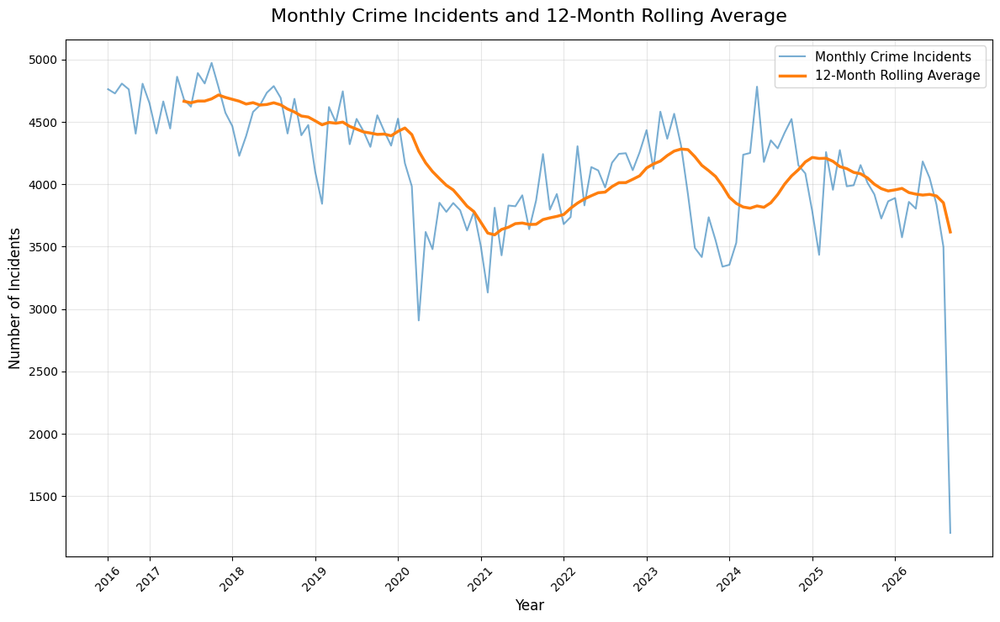

In [ ]:
plt.figure(figsize=(12, 7.5))

plt.plot(range(len(monthly_crimes)), monthly_crimes['Incident_Count'], label='Monthly Crime Incidents', alpha=0.6)
plt.plot(range(len(monthly_crimes)), monthly_crimes['Rolling_Average'], label='12-Month Rolling Average', linewidth=2.5)

plt.title('Monthly Crime Incidents and 12-Month Rolling Average', fontsize=16, pad=15)
plt.xlabel('Year', fontsize=12)
plt.ylabel('Number of Incidents', fontsize=12)

year_positions = monthly_crimes.groupby('Year').head(1).index
year_labels = monthly_crimes.loc[year_positions, 'Year']

plt.xticks(year_positions, year_labels, rotation=45)
plt.legend(fontsize=11)
plt.grid(alpha=0.3)
plt.tick_params(axis='both', labelsize=10)
plt.tight_layout()
plt.show()


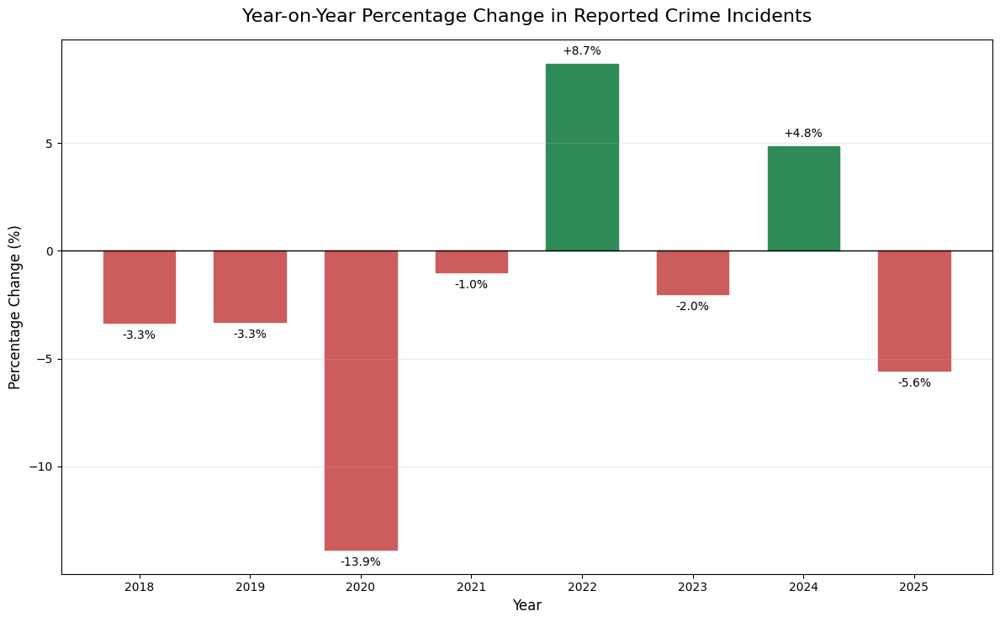

In [ ]:
annual_crimes = df_eda.groupby('Year').size().reset_index(name='Incident_Count')
annual_crimes = annual_crimes[(annual_crimes['Year'] >= 2017) & (annual_crimes['Year'] <= 2025)].copy()
annual_crimes['Percentage_Change'] = annual_crimes['Incident_Count'].pct_change() * 100

plt.figure(figsize=(12, 7.5))

bars = plt.bar(annual_crimes['Year'].astype(str), annual_crimes['Percentage_Change'], width=0.65)

for bar, change in zip(bars, annual_crimes['Percentage_Change']):
    bar.set_color('seagreen' if change > 0 else 'indianred')
    plt.text(bar.get_x() + bar.get_width() / 2, change + (0.3 if change > 0 else -0.3), f'{change:+.1f}%', ha='center', va='bottom' if change > 0 else 'top', fontsize=10)

plt.axhline(y=0, color='black', linewidth=1)
plt.title('Year-on-Year Percentage Change in Reported Crime Incidents', fontsize=16, pad=15)
plt.xlabel('Year', fontsize=12)
plt.ylabel('Percentage Change (%)', fontsize=12)
plt.xticks(fontsize=10)
plt.yticks(fontsize=10)
plt.grid(axis='y', alpha=0.25)
plt.tight_layout()
plt.show()


## Question 2.

To what extent do reported crime incidents exhibit recurring monthly or seasonal patterns?

In [ ]:
complete_years_monthly = monthly_crimes[(monthly_crimes['Year'] >= 2017) & (monthly_crimes['Year'] <= 2025)].copy()

In [ ]:
import calendar

complete_years_monthly['Month_Name'] = complete_years_monthly['Month'].apply(lambda x: calendar.month_abbr[x])
month_order = ['Jan', 'Feb', 'Mar', 'Apr', 'May', 'Jun', 'Jul', 'Aug', 'Sep', 'Oct', 'Nov', 'Dec']

In [ ]:
fig = px.box(complete_years_monthly, x='Month_Name', y='Incident_Count', color='Month_Name', category_orders={'Month_Name': month_order}, points=False, hover_data=['Year'], title='Monthly Distribution of Reported Crime Incidents (2017–2025)', labels={'Month_Name': 'Calendar Month', 'Incident_Count': 'Number of Incidents'})

fig.update_layout(template='plotly_white', showlegend=False, title_x=0.5, width=1200, height=750, font=dict(family='Arial', size=12), title_font=dict(size=20), xaxis_title_font=dict(size=14), yaxis_title_font=dict(size=14), margin=dict(l=80, r=60, t=100, b=80))

fig.update_traces(boxmean=True)

fig.show()

In [ ]:
monthly_heatmap = complete_years_monthly.pivot(index='Year', columns='Month', values='Incident_Count')

In [ ]:
month_names = ['January', 'February', 'March', 'April', 'May', 'June', 'July', 'August', 'September', 'October', 'November', 'December']

fig = px.imshow(monthly_heatmap, labels={'x': 'Month', 'y': 'Year', 'color': 'Number of Incidents'}, x=month_names, y=monthly_heatmap.index, color_continuous_scale='YlOrRd', aspect='auto', text_auto=True, title='Monthly Distribution of Reported Crime Incidents (2017–2025)')

fig.update_layout(template='plotly_white', title_x=0.5, width=1200, height=750, font=dict(family='Arial', size=12), title_font=dict(size=20), xaxis_title_font=dict(size=14), yaxis_title_font=dict(size=14), margin=dict(l=80, r=80, t=100, b=100))

fig.show()

## Question 3.

How does the temporal concentration of reported crime vary across weekdays, weekends and different hours of the day?

In [ ]:
df_eda['Day'] = df_eda['Start_Date_Time'].dt.day_name()
df_eda['Hour'] = df_eda['Start_Date_Time'].dt.hour
weekday_order = ['Monday', 'Tuesday', 'Wednesday', 'Thursday', 'Friday', 'Saturday', 'Sunday']

In [ ]:
day_hour_crimes = df_eda.groupby(['Day', 'Hour']).size().reset_index(name='Incident_Count')

In [ ]:
day_hour_pivot = day_hour_crimes.pivot(index='Day', columns='Hour', values='Incident_Count')
day_hour_pivot = day_hour_pivot.reindex(weekday_order)
hour_labels = ['12 AM', '1 AM', '2 AM', '3 AM', '4 AM', '5 AM', '6 AM', '7 AM', '8 AM', '9 AM', '10 AM', '11 AM', '12 PM', '1 PM', '2 PM', '3 PM', '4 PM', '5 PM', '6 PM', '7 PM', '8 PM', '9 PM', '10 PM', '11 PM']

In [ ]:
fig = px.imshow(day_hour_pivot, labels={'x': 'Hour of the Day', 'y': 'Day of the Week', 'color': 'Number of Incidents'}, x=hour_labels, y=weekday_order, color_continuous_scale='YlOrRd', aspect='auto', title='Distribution of Crime Incidents by Day and Hour')
fig.update_layout(template='plotly_white', title_x=0.5, width=1200, height=750, font=dict(family='Arial', size=12), title_font=dict(size=20), xaxis_title_font=dict(size=14), yaxis_title_font=dict(size=14), margin=dict(l=90, r=80, t=100, b=90))
fig.show()

In [ ]:
hourly_crimes = df_eda.groupby('Hour').size().reset_index(name='Incident_Count').sort_values('Hour')

In [ ]:
midnight_hour_records = df_eda[df_eda['Hour'] == 0]
midnight_records = df_eda[df_eda['Start_Date_Time'].dt.strftime('%H:%M:%S') == '00:00:00']
midnight_percentage = len(midnight_records) / len(midnight_hour_records) * 100
valid_midnight_records = midnight_records.dropna(subset=['Dispatch Date / Time', 'Start_Date_Time']).copy()
different_dates_percentage = (valid_midnight_records['Dispatch Date / Time'].dt.date != valid_midnight_records['Start_Date_Time'].dt.date).mean() * 100
print(f"Exact midnight timestamps among midnight-hour records: {midnight_percentage:.2f}%")
print(f"Different dispatch and start dates among valid exact-midnight records: {different_dates_percentage:.2f}%")

Exact midnight timestamps among midnight-hour records: 59.06%
Different dispatch and start dates among valid exact-midnight records: 76.82%


In [ ]:
angles = np.arange(0, 360, 15)
radii = np.sqrt(hourly_crimes['Incident_Count'])
fig = go.Figure()
fig.add_trace(go.Barpolar(r=radii, theta=angles, width=[15] * 24, customdata=hourly_crimes['Incident_Count'], marker=dict(color=hourly_crimes['Incident_Count'], colorscale='YlOrRd', showscale=True, colorbar=dict(title='Incidents')), hovertemplate='<b>%{text}</b><br>Incidents: %{customdata:,}<extra></extra>', text=hour_labels))
fig.update_layout(title='Nightingale Rose Chart: Hourly Distribution of Crime Incidents', title_x=0.5, template='plotly_white', font=dict(family='Arial', size=12), title_font=dict(size=20), polar=dict(angularaxis=dict(tickmode='array', tickvals=angles, ticktext=hour_labels, rotation=90, direction='clockwise'), radialaxis=dict(visible=True, tickmode='array', tickvals=np.sqrt([5000, 10000, 15000, 20000, 25000, 30000, 35000]), ticktext=['5k', '10k', '15k', '20k', '25k', '30k', '35k'], title='Incident count')), width=900, height=750, margin=dict(l=70, r=100, t=100, b=70))
fig.show()

The weekday-hour heatmap reveals variations in reported crime volumes across different days and times, highlighting periods with relatively higher and lower incident counts. The Nightingale Rose chart provides a complementary overview of the hourly distribution, making it easier to identify the hours with the greatest recorded incident volumes.

An important limitation concerns the concentration of incidents recorded at exactly midnight (00:00:00). Further investigation found that 59.06% of incidents assigned to the midnight hour had timestamps recorded at exactly 00:00:00. Among those records with both dispatch and start dates available, 76.82% had different dates. This may reflect delays between an incident occurring and being reported or recorded, or the use of estimated or imprecise occurrence times. However, the dataset does not establish the reason for these differences.

Consequently, the midnight peak should be interpreted cautiously and should not automatically be considered evidence that most incidents occurred at that precise time. More broadly, the analysis describes the recorded start times in the dataset, which may not always represent the exact times at which crimes occurred.

## Question 4.

To what extent are reported incidents concentrated among a small number of crime categories?

In [ ]:
crime_category_counts = df_eda['Crime Name2'].value_counts().reset_index()
crime_category_counts.columns = ['Crime_Category', 'Incident_Count']
crime_category_counts['Percentage'] = crime_category_counts['Incident_Count'] / len(df_eda) * 100
crime_category_counts['Cumulative_Count'] = crime_category_counts['Incident_Count'].cumsum()
crime_category_counts['Cumulative_Percentage'] = crime_category_counts['Cumulative_Count'] / len(df_eda) * 100
categories_for_80 = (crime_category_counts['Cumulative_Percentage'] >= 80).idxmax() + 1
print(f"Number of categories accounting for at least 80% of incidents: {categories_for_80}")

Number of categories accounting for at least 80% of incidents: 13


In [ ]:
top_20 = crime_category_counts.head(20).copy()
other_count = crime_category_counts.iloc[20:]['Incident_Count'].sum()
other_row = pd.DataFrame({'Crime_Category': ['Other Categories'], 'Incident_Count': [other_count]})
pareto_data = pd.concat([top_20[['Crime_Category', 'Incident_Count']], other_row], ignore_index=True)
pareto_data['Percentage'] = pareto_data['Incident_Count'] / len(df_eda) * 100
pareto_data['Cumulative_Percentage'] = pareto_data['Percentage'].cumsum()

In [ ]:
fig = go.Figure()
fig.add_trace(go.Bar(x=pareto_data['Crime_Category'], y=pareto_data['Incident_Count'], name='Incident Count', marker_color='steelblue', yaxis='y', hovertemplate='<b>%{x}</b><br>Incidents: %{y:,}<extra></extra>'))
fig.add_trace(go.Scatter(x=pareto_data['Crime_Category'], y=pareto_data['Cumulative_Percentage'], name='Cumulative Percentage', mode='lines+markers', marker=dict(size=7), line=dict(width=3, color='darkorange'), yaxis='y2', hovertemplate='<b>%{x}</b><br>Cumulative: %{y:.2f}%<extra></extra>'))
fig.add_hline(y=80, line_dash='dash', line_color='red', annotation_text='80% threshold', annotation_position='top left', yref='y2')
fig.update_layout(title='Pareto Analysis of the Top 20 Crime Categories and Other Categories', title_x=0.5, template='plotly_white', font=dict(family='Arial', size=12), title_font=dict(size=20), xaxis=dict(title='Crime Category', title_font=dict(size=14), tickangle=-55, automargin=True), yaxis=dict(title='Number of Incidents', title_font=dict(size=14), side='left'), yaxis2=dict(title='Cumulative Percentage (%)', title_font=dict(size=14), overlaying='y', side='right', range=[0, 105], ticksuffix='%'), legend=dict(orientation='h', yanchor='bottom', y=1.02, xanchor='center', x=0.5), width=1200, height=750, margin=dict(l=90, r=90, t=120, b=190))
fig.show()

In [ ]:
treemap_top20 = crime_category_counts[crime_category_counts['Crime_Category'] != 'All Other Offenses'].head(20).copy()
all_other_offenses = crime_category_counts[crime_category_counts['Crime_Category'] == 'All Other Offenses'].copy()
treemap_data = pd.concat([treemap_top20, all_other_offenses], ignore_index=True)

In [ ]:
fig = px.treemap(treemap_data, path=['Crime_Category'], values='Incident_Count', color='Incident_Count', color_continuous_scale='Blues', custom_data=['Percentage'], title='Distribution of the Top 20 Crime Categories and All Other Offenses')
fig.update_traces(hovertemplate='<b>%{label}</b><br>Incidents: %{value:,}<br>Percentage of all incidents: %{customdata[0]:.2f}%<extra></extra>', textinfo='label+percent entry')
fig.update_layout(title_x=0.5, template='plotly_white', width=1200, height=750, font=dict(family='Arial', size=12), title_font=dict(size=20), margin=dict(l=60, r=60, t=100, b=60))
fig.show()

## Question 5.

How have the relative prominence and frequency of different crime categories changed over time?

In [ ]:
yearly_category_counts = df_eda[df_eda['Year'].between(2017, 2025)].groupby(['Year', 'Crime Name2']).size().reset_index(name='Incident_Count')

In [ ]:
selected_categories = ['Hacking/Computer Invasion', 'Motor Vehicle Theft', 'Shoplifting', 'Impersonation', 'Drug/Narcotic Violations']
all_category_yearly = yearly_category_counts.pivot_table(index='Year', columns='Crime Name2', values='Incident_Count', fill_value=0)

In [ ]:
all_category_ranks = all_category_yearly.rank(axis=1, ascending=False, method='min')

In [ ]:
fig = go.Figure()
for category in all_category_ranks.columns:
    if category not in selected_categories:
        fig.add_trace(go.Scatter(x=all_category_ranks.index, y=all_category_ranks[category], mode='lines', name=category, line=dict(color='lightgrey', width=1), opacity=0.45, showlegend=False, hovertemplate=f'<b>{category}</b><br>Year: %{{x}}<br>Rank: %{{y}}<extra></extra>'))
for category in selected_categories:
    fig.add_trace(go.Scatter(x=all_category_ranks.index, y=all_category_ranks[category], mode='lines+markers', name=category, line=dict(width=3), marker=dict(size=7), hovertemplate=f'<b>{category}</b><br>Year: %{{x}}<br>Rank: %{{y}}<extra></extra>'))
fig.update_layout(title='Changes in Crime Category Rankings (2017–2025)', title_x=0.5, template='plotly_white', font=dict(family='Arial', size=12), title_font=dict(size=20), xaxis=dict(title='Year', title_font=dict(size=14), dtick=1), yaxis=dict(title='Ranking (1 = Highest)', title_font=dict(size=14), autorange='reversed', dtick=5), legend=dict(title='Selected Categories', orientation='v', x=1.02, y=1), width=1200, height=750, margin=dict(l=90, r=220, t=100, b=80), hovermode='closest')
fig.show()

In [ ]:
small_multiple_data = yearly_category_counts[yearly_category_counts['Crime Name2'].isin(selected_categories)].copy()
small_multiple_plot_data = small_multiple_data.pivot(index='Year', columns='Crime Name2', values='Incident_Count').reindex(index=range(2017, 2026), columns=selected_categories).fillna(0).reset_index().melt(id_vars='Year', var_name='Crime_Category', value_name='Incident_Count')

In [ ]:
fig = px.line(small_multiple_plot_data, x='Year', y='Incident_Count', color='Crime_Category', facet_col='Crime_Category', facet_col_wrap=2, markers=True, title='Yearly Trends in Selected Crime Categories (2017–2025)', labels={'Year': 'Year', 'Incident_Count': 'Number of Incidents', 'Crime_Category': 'Crime Category'}, hover_data={'Crime_Category': False})
fig.update_yaxes(matches=None, showticklabels=True, title_font=dict(size=14))
fig.update_xaxes(dtick=1, title_font=dict(size=14))
fig.update_traces(line=dict(width=2.5), marker=dict(size=7), hovertemplate='Year: %{x}<br>Incidents: %{y:,.0f}<extra></extra>')
fig.for_each_annotation(lambda a: a.update(text=a.text.split('=')[-1]))
fig.update_layout(template='plotly_white', title_x=0.5, title_font=dict(size=20), font=dict(family='Arial', size=12), showlegend=False, width=1200, height=900, margin=dict(l=90, r=60, t=110, b=80))
fig.show()

## Question 6.

How does the volume and distribution of reported crime incidents vary across police districts, and which districts account for the greatest share of recorded incidents?

In [133]:
district_counts = df_eda['Police District Name'].value_counts().reset_index()
district_counts.columns = ['Police_District', 'Incident_Count']

In [134]:
district_comparison = district_counts[~district_counts['Police_District'].isin(['Unknown', 'OTHER'])].copy()
district_comparison['District_Percentage'] = district_comparison['Incident_Count'] / district_comparison['Incident_Count'].sum() * 100

In [135]:
district_plot = district_comparison.sort_values('Incident_Count', ascending=True).copy()
fig = go.Figure()
for _, row in district_plot.iterrows():
    fig.add_trace(go.Scatter(x=[0, row['Incident_Count']], y=[row['Police_District'], row['Police_District']], mode='lines', line=dict(color='lightgrey', width=3), showlegend=False, hoverinfo='skip'))
fig.add_trace(go.Scatter(x=district_plot['Incident_Count'], y=district_plot['Police_District'], mode='markers+text', marker=dict(size=12), text=district_plot['Incident_Count'].map(lambda x: f'{x:,}'), textposition='middle right', textfont=dict(size=11), name='Incidents', hovertemplate='<b>%{y}</b><br>Incidents: %{x:,}<extra></extra>'))
fig.update_layout(title='Distribution of Reported Crime Incidents Across Police Districts', title_x=0.5, template='plotly_white', font=dict(family='Arial', size=12), title_font=dict(size=20), xaxis=dict(title='Number of Reported Incidents', title_font=dict(size=14), tickformat=',', range=[0, 120000]), yaxis=dict(title='Police District', title_font=dict(size=14)), margin=dict(l=130, r=130, t=100, b=80), width=1200, height=750, showlegend=False)
fig.show()

In [136]:
fig = px.pie(district_comparison, names='Police_District', values='Incident_Count', hole=0.48, title='Share of Reported Crime Incidents Across Police Districts', custom_data=['District_Percentage'])
fig.update_traces(textposition='inside', textinfo='percent', hovertemplate='<b>%{label}</b><br>Incidents: %{value:,}<br>Share: %{customdata[0]:.2f}%<extra></extra>', marker=dict(line=dict(color='white', width=2)))
fig.add_annotation(text=f"<b>{district_comparison['Incident_Count'].sum():,}</b><br>Incidents", x=0.5, y=0.5, showarrow=False, font=dict(size=17))
fig.update_layout(template='plotly_white', height=750, width=1200, title_x=0.5, title_font=dict(size=20), font=dict(family='Arial', size=12), legend_title_text='Police District', margin=dict(l=70, r=70, t=100, b=70))
fig.show()

## Question 7.

How do reported crime volumes and crime-category distributions vary across law-enforcement agencies over time?

In [137]:
main_agencies = ['MCPD', 'RCPD', 'GPD', 'TPPD']

Four law-enforcement agencies (MCPD, RCPD, GPD and TPPD) were selected for this analysis because they account for the vast majority of recorded incidents in the dataset. Together, these agencies represent approximately 99.9% of all incidents, while the remaining agencies contribute only a very small proportion. Focusing on these four agencies therefore provides a clearer and more meaningful comparison of crime-category composition and changes in reported incident volumes over time, without allowing very small agency counts to distort the visualisations.

In [138]:
agency_crime_percentages = pd.crosstab(df_eda[df_eda['Agency'].isin(main_agencies)]['Agency'], df_eda[df_eda['Agency'].isin(main_agencies)]['Crime Name1'], normalize='index') * 100
agency_plot_data = agency_crime_percentages.reset_index().melt(id_vars='Agency', var_name='Crime_Category', value_name='Percentage')

In [139]:
fig = px.bar(agency_plot_data, x='Percentage', y='Agency', color='Crime_Category', orientation='h', title='Crime-Category Composition Across Law-Enforcement Agencies', labels={'Percentage': 'Share of Reported Incidents (%)', 'Agency': 'Law-Enforcement Agency', 'Crime_Category': 'Crime Category'}, text=agency_plot_data['Percentage'].round(1))
fig.update_layout(template='plotly_white', barmode='stack', height=750, width=1200, title_x=0.5, title_font=dict(size=20), font=dict(family='Arial', size=12), xaxis=dict(title_font=dict(size=14), range=[0, 100], ticksuffix='%'), yaxis=dict(title_font=dict(size=14)), legend_title_text='Crime Category', margin=dict(l=110, r=70, t=100, b=80))
fig.update_traces(textposition='inside', insidetextanchor='middle')
fig.show()

In [140]:
agency_yearly_counts = df_eda[df_eda['Year'].between(2017, 2025) & df_eda['Agency'].isin(main_agencies)].groupby(['Year', 'Agency']).size().reset_index(name='Incident_Count')
agency_yearly_counts = agency_yearly_counts.sort_values(['Agency', 'Year']).copy()
agency_yearly_counts['Indexed_Count'] = agency_yearly_counts.groupby('Agency')['Incident_Count'].transform(lambda x: (x / x.iloc[0]) * 100)

**Note: 2017 is used as the baseline year (index = 100) for all agencies; subsequent values represent relative changes in recorded incident counts compared with 2017, not crime rates.**

In [141]:
fig = px.line(agency_yearly_counts, x='Year', y='Indexed_Count', color='Agency', markers=True, title='Relative Changes in Reported Crime Incidents by Agency (2017–2025)', labels={'Year': 'Year', 'Indexed_Count': 'Incident Index (2017 = 100)', 'Agency': 'Law-Enforcement Agency'})
fig.add_hline(y=100, line_dash='dash', line_color='grey', annotation_text='2017 baseline', annotation_position='bottom right')
fig.update_layout(template='plotly_white', height=750, width=1200, title_x=0.5, title_font=dict(size=20), font=dict(family='Arial', size=12), hovermode='x unified', legend_title_text='Agency', xaxis=dict(title_font=dict(size=14), dtick=1), yaxis=dict(title_font=dict(size=14)), margin=dict(l=90, r=100, t=110, b=80))
fig.update_traces(line=dict(width=2.5), marker=dict(size=7))
fig.show()

- MCPD: Fell to approximately 80% of its 2017 level in 2020–2021 and remained below its baseline through 2025.
- GPD: Experienced the sharpest early decline, reaching 63.83% in 2020, before partially recovering.
- RCPD: Recovered to 103.35% in 2024, almost returning to its 2017 level.
- TPPD: Increased substantially in 2023 and 2024, reaching 138.01% in 2024, before falling to 86.38% in 2025.
The TPPD increase followed by a sharp decline is particularly worth investigating. It could reflect genuine changes, reporting patterns or data-recording differences; we shouldn't assume the cause

## Question 8.

What patterns emerge in the occurrence and victim distribution of multiple-victim incidents?

In [142]:
victim_category_detail = df_eda.groupby('Crime Name2').agg(
    Total_Incidents=('Victims', 'size'),
    Multiple_Victim_Incidents=('Victims', lambda x: (x > 1).sum())
).reset_index()

victim_category_detail['Multiple_Victim_Percentage'] = victim_category_detail['Multiple_Victim_Incidents'] / victim_category_detail['Total_Incidents'] * 100

victim_category_filtered = victim_category_detail[(victim_category_detail['Total_Incidents'] >= 100) & (victim_category_detail['Multiple_Victim_Incidents'] > 0)].copy()

top_victim_categories = victim_category_filtered.nlargest(15, 'Multiple_Victim_Percentage').sort_values('Multiple_Victim_Percentage', ascending=True)

In [143]:
fig = px.bar(top_victim_categories, x='Multiple_Victim_Percentage', y='Crime Name2', orientation='h', text='Multiple_Victim_Percentage', hover_data=['Total_Incidents', 'Multiple_Victim_Incidents'], title='Top 15 Crime Categories by Percentage of Multiple-Victim Incidents', labels={'Multiple_Victim_Percentage': 'Multiple-Victim Incidents (%)', 'Crime Name2': 'Crime Category'})

fig.update_traces(texttemplate='%{text:.2f}%', textposition='outside')

fig.update_layout(template='plotly_white', title_x=0.5, width=1200, height=750, font=dict(family='Arial', size=12), title_font=dict(size=20), xaxis_title_font=dict(size=14), yaxis_title_font=dict(size=14), showlegend=False, margin=dict(l=180, r=100, t=100, b=80))

fig.show()

In [144]:
multiple_victim_distribution = df_eda[df_eda['Victims'] > 1]['Victims'].value_counts().sort_index().reset_index()

multiple_victim_distribution.columns = ['Victim_Count', 'Incident_Count']

multiple_victim_distribution['Percentage'] = multiple_victim_distribution['Incident_Count'] / multiple_victim_distribution['Incident_Count'].sum() * 100

In [145]:
fig = px.bar(multiple_victim_distribution, x='Victim_Count', y='Incident_Count', text='Incident_Count', hover_data=['Percentage'], title='Distribution of Victim Counts Among Multiple-Victim Incidents', labels={'Victim_Count': 'Number of Victims', 'Incident_Count': 'Number of Incidents'}, log_y=True)

fig.update_traces(texttemplate='%{text:,}', textposition='outside')

fig.update_layout(template='plotly_white', title_x=0.5, width=1200, height=750, font=dict(family='Arial', size=12), title_font=dict(size=20), xaxis=dict(title_font=dict(size=14), tickmode='array', tickvals=multiple_victim_distribution['Victim_Count']), yaxis=dict(title='Number of Incidents (Logarithmic Scale)', title_font=dict(size=14)), showlegend=False, margin=dict(l=100, r=80, t=100, b=80))

fig.show()

A logarithmic scale was applied to the y-axis because the distribution of multiple-victim incidents was highly right-skewed. Incidents involving two victims accounted for the vast majority of observations, while incidents involving larger numbers of victims occurred considerably less frequently. The logarithmic scale improves the visibility of these less frequent categories while retaining all observations. The original incident counts remain unchanged; only the visual axis scale is adjusted.

## Question 9.

How do the geographical patterns of reported crime incidents vary across different crime categories?

In [152]:
geo_data = df_eda.dropna(subset=['Latitude', 'Longitude']).copy()

In [ ]:
pip install h3

In [153]:
geo_data['H3_Cell'] = geo_data.apply(lambda row: h3.latlng_to_cell(row['Latitude'], row['Longitude'], 8), axis=1)

hexagon_counts = geo_data.groupby('H3_Cell').size().reset_index(name='Incident_Count')
hexagon_counts['Log_Count'] = np.log1p(hexagon_counts['Incident_Count'])

In [154]:
hex_features = []

for _, row in hexagon_counts.iterrows():
    boundary = h3.cell_to_boundary(row['H3_Cell'])
    coordinates = [[lon, lat] for lat, lon in boundary]
    coordinates.append(coordinates[0])
    hex_features.append({'type': 'Feature', 'id': row['H3_Cell'], 'properties': {'incident_count': int(row['Incident_Count'])}, 'geometry': {'type': 'Polygon', 'coordinates': [coordinates]}})

hex_geojson = {'type': 'FeatureCollection', 'features': hex_features}

In [155]:
fig = go.Figure(go.Choroplethmapbox(geojson=hex_geojson, locations=hexagon_counts['H3_Cell'], z=hexagon_counts['Log_Count'], featureidkey='id', colorscale='YlOrRd', marker_opacity=0.5, marker_line_width=0.3, customdata=hexagon_counts[['Incident_Count']], hovertemplate='Reported incidents: %{customdata[0]:,}<extra></extra>', colorbar=dict(title='Log incident count')))

fig.update_layout(title='Geographical Hotspots of Reported Crime Incidents', title_x=0.5, mapbox=dict(style='open-street-map', center=dict(lat=39.14, lon=-77.20), zoom=9), template='plotly_white', width=1200, height=750, font=dict(family='Arial', size=12), title_font=dict(size=20), margin=dict(l=10, r=10, t=80, b=10))

fig.show()

In [156]:
grid_size = 100

longitude_bins = np.linspace(geo_data['Longitude'].min(), geo_data['Longitude'].max(), grid_size + 1)
latitude_bins = np.linspace(geo_data['Latitude'].min(), geo_data['Latitude'].max(), grid_size + 1)

crime_density, longitude_edges, latitude_edges = np.histogram2d(geo_data['Longitude'], geo_data['Latitude'], bins=[longitude_bins, latitude_bins])

In [157]:
fig_v17_log = go.Figure(data=go.Heatmap(x=(longitude_edges[:-1] + longitude_edges[1:]) / 2, y=(latitude_edges[:-1] + latitude_edges[1:]) / 2, z=np.where(crime_density.T > 0, np.log1p(crime_density.T), np.nan), colorscale='YlOrRd', colorbar=dict(title='Log Incident Count', tickvals=np.log1p([1, 10, 100, 1000, 5000, 10000]), ticktext=['1', '10', '100', '1,000', '5,000', '10,000']), hovertemplate='Longitude: %{x:.4f}<br>Latitude: %{y:.4f}<br>Log density: %{z:.2f}<extra></extra>'))

fig_v17_log.update_layout(title=dict(text='Geographical Distribution of Reported Crime Incidents', x=0.5), xaxis_title='Longitude', yaxis_title='Latitude', template='plotly_white', width=1200, height=750, font=dict(family='Arial', size=12), title_font=dict(size=20), xaxis_title_font=dict(size=14), yaxis_title_font=dict(size=14), margin=dict(l=90, r=100, t=100, b=80))

fig_v17_log.show()

In [158]:
selected_categories = ['Theft From Motor Vehicle', 'Simple Assault', 'Theft from Building', 'Destruction/Damage/Vandalism of Property', 'Drug/Narcotic Violations']

In [159]:
category_density = {}

for category in selected_categories:
    category_data = geo_data[geo_data['Crime Name2'] == category]
    density, _, _ = np.histogram2d(category_data['Longitude'], category_data['Latitude'], bins=[longitude_bins, latitude_bins])
    category_density[category] = density

In [160]:
category_density_pct = {}

for category, density in category_density.items():
    category_density_pct[category] = (density / density.sum()) * 100

positive_values = np.concatenate([values[values > 0] for values in category_density_pct.values()])

z_min = np.log10(positive_values.min())
z_max = np.log10(positive_values.max())

In [161]:
fig_v18 = make_subplots(rows=2, cols=3, subplot_titles=['Theft From Motor Vehicle', 'Simple Assault', 'Theft from Building', 'Property Damage / Vandalism', 'Drug / Narcotic Violations'], horizontal_spacing=0.10, vertical_spacing=0.16)

positions = [(1, 1), (1, 2), (1, 3), (2, 1), (2, 2)]

for i, category in enumerate(selected_categories):
    row, col = positions[i]
    values = category_density_pct[category]
    z_values = np.where(values > 0, np.log10(np.maximum(values, 1e-10)), np.nan)

    fig_v18.add_trace(go.Heatmap(x=(longitude_edges[:-1] + longitude_edges[1:]) / 2, y=(latitude_edges[:-1] + latitude_edges[1:]) / 2, z=z_values.T, colorscale='YlOrRd', zmin=z_min, zmax=z_max, showscale=(i == 0), colorbar=dict(title='Log10 of<br>category share (%)', x=1.02), hovertemplate='Longitude: %{x:.4f}<br>Latitude: %{y:.4f}<br>Log10 share: %{z:.3f}<extra></extra>'), row=row, col=col)

for row, col in positions:
    fig_v18.update_xaxes(title_text='Longitude', range=[longitude_edges[0], longitude_edges[-1]], row=row, col=col)
    fig_v18.update_yaxes(title_text='Latitude', range=[latitude_edges[0], latitude_edges[-1]], row=row, col=col)

fig_v18.update_layout(title=dict(text='Geographical Distribution of Selected Crime Categories', x=0.5), template='plotly_white', width=1400, height=900, font=dict(family='Arial', size=12), title_font=dict(size=20), margin=dict(l=80, r=120, t=100, b=80))

fig_v18.show()

chart shows the percentage distribution of incidents within each crime category across spatial grid cells, rather than the absolute number of incidents.


The logarithmic colour scale (Log10) transforms the percentage values to improve the visibility of differences in spatial distribution. The relationship between the original percentages and their Log10 values is illustrated below:

| Actual Percentage | Log10 Value |
|---:|---:|
| 10% | 1 |
| 1% | 0 |
| 0.1% | -1 |
| 0.01% | -2 |

Negative Log10 values do not indicate negative percentages. They represent positive percentages smaller than 1%.

In [171]:

fig = make_subplots(rows=2, cols=3, subplot_titles=selected_categories)

for i, category in enumerate(selected_categories):
    row = i // 3 + 1
    col = i % 3 + 1
    density_pct = category_density_pct[category]
    log_density = np.where(density_pct > 0, np.log10(density_pct), np.nan)

    fig.add_trace(go.Heatmap(
        x=(longitude_edges[:-1] + longitude_edges[1:]) / 2,
        y=(latitude_edges[:-1] + latitude_edges[1:]) / 2,
        z=log_density.T,
        customdata=density_pct.T,
        colorscale='YlOrRd',
        zmin=z_min,
        zmax=z_max,
        showscale=(i == 0),
        colorbar=dict(title='Log10 Share') if i == 0 else None,
        hovertemplate='Longitude: %{x:.4f}<br>Latitude: %{y:.4f}<br>Share of category incidents: %{customdata:.4f}%<extra></extra>'
    ), row=row, col=col)

fig.update_layout(
    title=dict(text='Geographical Distribution of Selected Crime Categories', x=0.5),
    template='plotly_white',
    width=1400,
    height=900,
    font=dict(family='Arial', size=12),
    title_font=dict(size=20),
    margin=dict(l=70, r=100, t=110, b=70)
)

fig.update_xaxes(title_text='Longitude')
fig.update_yaxes(title_text='Latitude')
fig.show()


/tmp/ipykernel_1888/4248500334.py:7: RuntimeWarning:

divide by zero encountered in log10



**Interpretation of Share of Category Incidents**

The hover information displays the percentage share of incidents within each crime category that fall into a particular geographical grid cell. This percentage is calculated by dividing the number of incidents in a grid cell by the total number of incidents recorded for that specific crime category across the study area, then multiplying by 100.

This normalisation allows the geographical distribution of different crime categories to be compared more fairly, regardless of differences in their overall incident volumes. A higher percentage indicates that a greater proportion of incidents within that crime category are concentrated in that particular grid cell.

**A cell showing 5% does not mean that 5% of all crimes in that location belong to that category. It means that 5% of all recorded incidents of that particular category occurred in that cell.**

In [162]:
fig = go.Figure()

fig.add_trace(go.Scattermapbox(lat=geo_data['Latitude'], lon=geo_data['Longitude'], mode='markers', marker=dict(size=4, color='#D35400', opacity=0.35), hovertemplate='Latitude: %{lat:.5f}<br>Longitude: %{lon:.5f}<extra></extra>'))

fig.update_layout(title='Geographical Distribution of Reported Crime Incidents', title_x=0.5, mapbox=dict(style='open-street-map', center=dict(lat=39.14, lon=-77.20), zoom=9), template='plotly_white', width=1200, height=750, font=dict(family='Arial', size=12), title_font=dict(size=20), margin=dict(l=10, r=10, t=80, b=10), showlegend=False)

fig.show()

In [163]:
scatter_data = geo_data[geo_data['Crime Name2'].isin(selected_categories)].copy()

In [164]:
fig = make_subplots(rows=2, cols=3, specs=[[{'type': 'mapbox'}, {'type': 'mapbox'}, {'type': 'mapbox'}], [{'type': 'mapbox'}, {'type': 'mapbox'}, None]], subplot_titles=selected_categories, horizontal_spacing=0.02, vertical_spacing=0.08)

for i, category in enumerate(selected_categories):
    row = 1 if i < 3 else 2
    col = (i % 3) + 1 if i < 3 else i - 2
    category_data = scatter_data[scatter_data['Crime Name2'] == category]

    fig.add_trace(go.Scattermapbox(lat=category_data['Latitude'], lon=category_data['Longitude'], mode='markers', marker=dict(size=4, color='#D35400', opacity=0.35), name=category, hovertemplate='<b>' + category + '</b><br>Latitude: %{lat:.5f}<br>Longitude: %{lon:.5f}<extra></extra>', showlegend=False), row=row, col=col)

map_settings = dict(style='open-street-map', center=dict(lat=39.14, lon=-77.20), zoom=9)

fig.update_layout(mapbox=map_settings, mapbox2=map_settings, mapbox3=map_settings, mapbox4=map_settings, mapbox5=map_settings, title=dict(text='Geographical Distribution of Selected Crime Categories', x=0.5), template='plotly_white', width=1500, height=950, font=dict(family='Arial', size=12), title_font=dict(size=20), margin=dict(l=20, r=30, t=100, b=30))

fig.show()

## Question 10.

How does the composition of reported crime categories differ across the types of places where incidents occur?

In [165]:
place_counts = df_eda['Place'].value_counts().head(20).sort_values()
place_percentages = place_counts / len(df_eda) * 100

In [166]:
fig = go.Figure(go.Bar(
    x=place_counts.values,
    y=place_counts.index,
    orientation='h',
    marker_color=[
        '#E07A5F' if place == 'Other/Unknown' else '#4C78A8'
        for place in place_counts.index
    ],
    customdata=place_percentages.values,
    hovertemplate='Place: %{y}<br>Incidents: %{x:,}<br>Share of all incidents: %{customdata:.2f}%<extra></extra>'
))

fig.update_layout(
    title=dict(text='Top 20 Places by Reported Crime Incidents', x=0.5),
    xaxis_title='Number of Reported Incidents',
    yaxis_title='Place Category',
    template='plotly_white',
    width=1200,
    height=750,
    font=dict(family='Arial', size=12),
    title_font=dict(size=20),
    xaxis_title_font=dict(size=14),
    yaxis_title_font=dict(size=14),
    margin=dict(l=180, r=40, t=90, b=70)
)

fig.show()

In [167]:
top_places = df_eda['Place'].value_counts().head(15).index

v20_data = df_eda[['Crime Name1', 'Place']].copy()
v20_data['Place_Group'] = v20_data['Place'].where(v20_data['Place'].isin(top_places), 'Other Places')

sankey_counts = v20_data.groupby(['Crime Name1', 'Place_Group']).size().reset_index(name='Incident_Count')

In [168]:
crime_categories = sankey_counts['Crime Name1'].unique().tolist()
place_categories = sankey_counts['Place_Group'].unique().tolist()
labels = crime_categories + place_categories

label_indices = {label: index for index, label in enumerate(labels)}
source = sankey_counts['Crime Name1'].map(label_indices).tolist()
target = sankey_counts['Place_Group'].map(label_indices).tolist()
values = sankey_counts['Incident_Count'].tolist()

In [169]:
fig = go.Figure(go.Sankey(
    arrangement='snap',
    node=dict(
        pad=20,
        thickness=20,
        line=dict(color='grey', width=0.5),
        label=labels
    ),
    link=dict(
        source=source,
        target=target,
        value=values
    )
))

fig.update_layout(
    title=dict(text='Flow of Reported Crime Incidents Across Place Types', x=0.5),
    template='plotly_white',
    font=dict(family='Arial', size=11),
    title_font=dict(size=20),
    width=1200,
    height=750,
    margin=dict(l=30, r=30, t=90, b=40)
)

fig.show()